# Market Efficiency Analysis - Final

**Analyzes betting strategy performance vs market baseline**

Author: Ecem Yildirim  
Date: March 2026

In [4]:
import pandas as pd
import numpy as np
from sklearn.metrics import log_loss

print("="*80)
print("MARKET EFFICIENCY ANALYSIS")
print("="*80)

MARKET EFFICIENCY ANALYSIS


In [5]:
from pathlib import Path

# Data path
data_path = Path('../data/processed/model_ready/merged_predictions_odds.csv')

# Load data
merged = pd.read_csv(data_path)

print(f"\nLoaded {len(merged):,} rows")
print(f"Unique matches: {merged['match_id'].nunique():,}")
print(f"Date range: {merged['Date'].min()} to {merged['Date'].max()}")

# Calculate time span
dates = pd.to_datetime(merged['Date'])
years_span = (dates.max() - dates.min()).days / 365.25
print(f"Time span: {years_span:.1f} years")

merged = merged.drop(columns='won').copy()


Loaded 9,950 rows
Unique matches: 4,972
Date range: 2015-01-06 to 2024-11-13
Time span: 9.9 years


## 1. Market Baseline: Betting on Favorites

Naive strategy - always bet on the market favorite

In [35]:
print("\n" + "="*80)
print("BASELINE: Betting on Market Favorites")
print("="*80)

# Use unique matches only
baseline_unique = merged.drop_duplicates(subset='match_id', keep='first').copy()

baseline_returns = []
baseline_wins = 0

for _, row in baseline_unique.iterrows():
    # Calculate who is favorite
    winner_market_prob = 1 / row['AvgW']
    loser_market_prob = 1 / row['AvgL']
    
    # Bet on favorite
    if winner_market_prob > loser_market_prob:
        # Winner is favorite → we win
        profit = 100 * (row['AvgW'] - 1)
        baseline_wins += 1
    else:
        # Loser was favorite → we lose
        profit = -100
    
    baseline_returns.append(profit / 100)

# Calculate metrics
baseline_returns_array = np.array(baseline_returns)
baseline_bets = len(baseline_returns)
baseline_total_profit = baseline_returns_array.sum() * 100
baseline_roi = (baseline_total_profit / (baseline_bets * 100)) * 100
baseline_win_rate = baseline_wins / baseline_bets

# Sharpe ratio (using sqrt(252) - industry standard)
baseline_sharpe = (baseline_returns_array.mean() / baseline_returns_array.std()) * np.sqrt(252)

# Annualized ROI
baseline_annual_roi = ((1 + baseline_roi/100) ** (1/years_span) - 1) * 100

# Logloss
baseline_logloss = log_loss(baseline_unique['y_true'], baseline_unique['market_prob'])

# Brier score
baseline_brier = np.mean((baseline_unique['market_prob'] - baseline_unique['y_true']) ** 2)

print(f"\nResults:")
print(f"  Total bets: {baseline_bets:,}")
print(f"  Wins: {baseline_wins:,}")
print(f"  Win rate: {baseline_win_rate:.1%}")
print(f"  Total profit: ${baseline_total_profit:,.2f}")
print(f"  Total ROI ({years_span:.1f} years): {baseline_roi:.2f}%")
print(f"  Annual ROI: {baseline_annual_roi:.2f}%")
print(f"  Sharpe ratio: {baseline_sharpe:.2f}")
print(f"  Log loss: {baseline_logloss:.4f}")
print(f"  Brier score: {baseline_brier:.4f}")

print(f"\n✓ Sanity check: Favorites won {baseline_win_rate:.1%} (expected: 55-70%)")


BASELINE: Betting on Market Favorites

Results:
  Total bets: 4,972
  Wins: 3,450
  Win rate: 69.4%
  Total profit: $-18,320.00
  Total ROI (9.9 years): -3.68%
  Annual ROI: -0.38%
  Sharpe ratio: -0.88
  Log loss: 0.5780
  Brier score: 0.1968

✓ Sanity check: Favorites won 69.4% (expected: 55-70%)


## 2. Model Strategies: Value Betting

Test conservative (edge > 0.05) and aggressive (edge > 0.20) strategies

In [43]:
def calculate_value_bets(df, edge_threshold, stake=100):
    """
    Calculate value bet performance for given edge threshold.
    Uses unique matches only.
    """
    # Get unique matches
    df_unique = df.drop_duplicates(subset='match_id', keep='first').copy()
    
    # Filter for value bets
    value_bets = df_unique[df_unique['edge'] > edge_threshold].copy()
    
    if len(value_bets) == 0:
        return None
    
    # Calculate profits
    profits = []
    wins = 0
    
    for _, row in value_bets.iterrows():
        if row['y_true'] == 1:
            # Bet on winner
            profit = stake * (row['AvgW'] - 1)
            wins += 1
        else:
            # Bet on loser → lose
            profit = -stake
        
        profits.append(profit)
    
    # Metrics
    profits_array = np.array(profits)
    total_profit = profits_array.sum()
    total_staked = len(profits) * stake
    roi = (total_profit / total_staked) * 100
    win_rate = wins / len(profits)
    
    # Sharpe ratio (sqrt(252) - industry standard)
    returns = profits_array / stake
    sharpe = (returns.mean() / returns.std()) * np.sqrt(252) if returns.std() > 0 else 0
    
    # Annualized ROI
    annual_roi = ((1 + roi/100) ** (1/years_span) - 1) * 100
    
    return {
        'threshold': edge_threshold,
        'num_bets': len(profits),
        'wins': wins,
        'win_rate': win_rate,
        'total_profit': total_profit,
        'total_staked': total_staked,
        'roi': roi,
        'annual_roi': annual_roi,
        'sharpe_ratio': sharpe,
        'value_bets_df': value_bets
    }

print("\n✓ Strategy function defined")


✓ Strategy function defined


## 3. Conservative Strategy (Edge > 0.05)

In [45]:
print("\n" + "="*80)
print("CONSERVATIVE STRATEGY: Edge > 0.05")
print("="*80)

results_05 = calculate_value_bets(merged, edge_threshold=0.05, stake=100)

if results_05:
    print(f"\nResults:")
    print(f"  Number of value bets: {results_05['num_bets']:,}")
    print(f"  Wins: {results_05['wins']:,}")
    print(f"  Win rate: {results_05['win_rate']:.1%}")
    print(f"  Total profit: ${results_05['total_profit']:,.2f}")
    print(f"  Total staked: ${results_05['total_staked']:,.2f}")
    print(f"  Total ROI ({years_span:.1f} years): {results_05['roi']:.2f}%")
    print(f"  Annual ROI: {results_05['annual_roi']:.2f}%")
    print(f"  Sharpe ratio: {results_05['sharpe_ratio']:.2f}")
    
    print(f"\n  Top 5 Value Bets:")
    print(f"  {'-'*78}")
    top_5 = results_05['value_bets_df'].nlargest(5, 'edge')
    for idx, row in top_5.iterrows():
        outcome = "✓ WON" if row['y_true'] == 1 else "✗ LOST"
        print(f"  {row['Date']}: {row['player_name']} vs {row['opponent_name']}")
        print(f"    Edge: {row['edge']:.1%} | Model: {row['model_prob']:.1%} | Market: {row['market_prob']:.1%} | {outcome}")


CONSERVATIVE STRATEGY: Edge > 0.05

Results:
  Number of value bets: 1,700
  Wins: 1,053
  Win rate: 61.9%
  Total profit: $72,388.00
  Total staked: $170,000.00
  Total ROI (9.9 years): 42.58%
  Annual ROI: 3.67%
  Sharpe ratio: 1.64

  Top 5 Value Bets:
  ------------------------------------------------------------------------------
  2017-03-11: Bagnis F. vs Benneteau J.
    Edge: 71.8% | Model: 93.5% | Market: 21.7% | ✓ WON
  2021-03-11: Basilashvili N. vs Federer R.
    Edge: 68.9% | Model: 89.5% | Market: 20.6% | ✓ WON
  2021-06-30: Nishioka Y. vs Isner J.
    Edge: 65.1% | Model: 81.9% | Market: 16.8% | ✓ WON
  2015-05-10: Murray A. vs Nadal R.
    Edge: 64.9% | Model: 95.2% | Market: 30.3% | ✓ WON
  2024-02-27: Cobolli F. vs Auger-Aliassime F.
    Edge: 63.3% | Model: 95.8% | Market: 32.5% | ✓ WON


## 4. Aggressive Strategy (Edge > 0.20)

In [46]:
print("\n" + "="*80)
print("AGGRESSIVE STRATEGY: Edge > 0.20")
print("="*80)

results_20 = calculate_value_bets(merged, edge_threshold=0.20, stake=100)

if results_20:
    print(f"\nResults:")
    print(f"  Number of value bets: {results_20['num_bets']:,}")
    print(f"  Wins: {results_20['wins']:,}")
    print(f"  Win rate: {results_20['win_rate']:.1%}")
    print(f"  Total profit: ${results_20['total_profit']:,.2f}")
    print(f"  Total staked: ${results_20['total_staked']:,.2f}")
    print(f"  Total ROI ({years_span:.1f} years): {results_20['roi']:.2f}%")
    print(f"  Annual ROI: {results_20['annual_roi']:.2f}%")
    print(f"  Sharpe ratio: {results_20['sharpe_ratio']:.2f}")
    
    print(f"\n  Top 10 Value Bets:")
    print(f"  {'-'*78}")
    top_10 = results_20['value_bets_df'].nlargest(10, 'edge')
    for idx, row in top_10.iterrows():
        outcome = "✓ WON" if row['y_true'] == 1 else "✗ LOST"
        print(f"  {row['Date']}: {row['player_name']} vs {row['opponent_name']}")
        print(f"    Edge: {row['edge']:.1%} | Model: {row['model_prob']:.1%} | Market: {row['market_prob']:.1%} | {outcome}")


AGGRESSIVE STRATEGY: Edge > 0.20

Results:
  Number of value bets: 705
  Wins: 449
  Win rate: 63.7%
  Total profit: $55,081.00
  Total staked: $70,500.00
  Total ROI (9.9 years): 78.13%
  Annual ROI: 6.03%
  Sharpe ratio: 2.00

  Top 10 Value Bets:
  ------------------------------------------------------------------------------
  2017-03-11: Bagnis F. vs Benneteau J.
    Edge: 71.8% | Model: 93.5% | Market: 21.7% | ✓ WON
  2021-03-11: Basilashvili N. vs Federer R.
    Edge: 68.9% | Model: 89.5% | Market: 20.6% | ✓ WON
  2021-06-30: Nishioka Y. vs Isner J.
    Edge: 65.1% | Model: 81.9% | Market: 16.8% | ✓ WON
  2015-05-10: Murray A. vs Nadal R.
    Edge: 64.9% | Model: 95.2% | Market: 30.3% | ✓ WON
  2024-02-27: Cobolli F. vs Auger-Aliassime F.
    Edge: 63.3% | Model: 95.8% | Market: 32.5% | ✓ WON
  2022-03-23: Cerundolo J.M. vs Lajovic D.
    Edge: 63.3% | Model: 77.3% | Market: 14.0% | ✓ WON
  2019-08-29: Gerasimov E. vs Schwartzman D.
    Edge: 61.9% | Model: 85.8% | Market: 23.9

## 5. Final Comparison Summary

In [47]:
print("\n" + "="*80)
print("STRATEGY COMPARISON")
print("="*80)

print(f"\n{'Strategy':<30s} {'Bets':>10s} {'Win Rate':>12s} {'Annual ROI':>12s} {'Sharpe':>10s}")
print("-" * 80)

print(f"{'Baseline (Favorites)':<30s} {baseline_bets:>10,} "
      f"{baseline_win_rate:>11.1%} {baseline_annual_roi:>11.2f}% {baseline_sharpe:>9.2f}")

if results_05:
    print(f"{'Conservative (Edge > 0.05)':<30s} {results_05['num_bets']:>10,} "
          f"{results_05['win_rate']:>11.1%} {results_05['annual_roi']:>11.2f}% {results_05['sharpe_ratio']:>9.2f}")

if results_20:
    print(f"{'Aggressive (Edge > 0.20)':<30s} {results_20['num_bets']:>10,} "
          f"{results_20['win_rate']:>11.1%} {results_20['annual_roi']:>11.2f}% {results_20['sharpe_ratio']:>9.2f}")

print("\n" + "="*80)
print("KEY FINDINGS")
print("="*80)

if results_05:
    edge_05 = results_05['annual_roi'] - baseline_annual_roi
    print(f"\n✓ Conservative strategy:")
    print(f"  - Outperforms baseline by {edge_05:+.2f} percentage points annually")
    print(f"  - {results_05['annual_roi']:.2f}% annual ROI vs {baseline_annual_roi:.2f}%")
    print(f"  - Sharpe {results_05['sharpe_ratio']:.2f} vs {baseline_sharpe:.2f}")

if results_20:
    edge_20 = results_20['annual_roi'] - baseline_annual_roi
    print(f"\n✓ Aggressive strategy:")
    print(f"  - Outperforms baseline by {edge_20:+.2f} percentage points annually")
    print(f"  - {results_20['annual_roi']:.2f}% annual ROI vs {baseline_annual_roi:.2f}%")
    print(f"  - Sharpe {results_20['sharpe_ratio']:.2f} vs {baseline_sharpe:.2f}")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)


STRATEGY COMPARISON

Strategy                             Bets     Win Rate   Annual ROI     Sharpe
--------------------------------------------------------------------------------
Baseline (Favorites)                4,972       69.4%       -0.38%     -0.88
Conservative (Edge > 0.05)          1,700       61.9%        3.67%      1.64
Aggressive (Edge > 0.20)              705       63.7%        6.03%      2.00

KEY FINDINGS

✓ Conservative strategy:
  - Outperforms baseline by +4.05 percentage points annually
  - 3.67% annual ROI vs -0.38%
  - Sharpe 1.64 vs -0.88

✓ Aggressive strategy:
  - Outperforms baseline by +6.41 percentage points annually
  - 6.03% annual ROI vs -0.38%
  - Sharpe 2.00 vs -0.88

ANALYSIS COMPLETE


In [33]:
df = pd.read_csv('../data/processed/model_ready/merged_predictions_odds.csv')
df = df.drop_duplicates(subset='match_id', keep='first')
top_bets = df[df['y_true']==1].nlargest(10, 'edge')

# Define major upset: market gave winner < 30% chance (big underdog)
# and model correctly predicted them to win

upsets = df[
    (df['market_prob'] < 0.30) &  # market thought they'd lose
    (df['y_true'] == 1) &  # they actually won
    (df['model_prob'] > 0.50)      # model correctly predicted win
].drop_duplicates(subset='match_id').copy()

print(f"Major upsets correctly predicted: {len(upsets)}")
upsets = upsets.sort_values('edge', ascending=False)
print(upsets[['match_id', 'model_prob', 'market_prob', 'y_true']].head(20))

Major upsets correctly predicted: 42
                                 match_id  model_prob  market_prob  y_true
2416        2017-03-11_BagnisF_BenneteauJ    0.935300     0.217391       1
5924    2021-03-11_BasilashviliN_FedererR    0.895474     0.206186       1
6326          2021-06-30_IsnerJ_NishiokaY    0.818719     0.168067       1
6978      2022-03-23_CerundoloJM_LajovicD    0.772866     0.139665       1
3705               2018-05-29_SockJ_ZoppJ    0.839202     0.221239       1
3838       2018-07-05_FabbianoT_WawrinkaS    0.900402     0.286533       1
7741      2022-10-31_BasilashviliN_HalysQ    0.847928     0.255102       1
8358  2023-06-26_CarballesBaenaR_IvashkaI    0.856117     0.268817       1
799         2015-09-01_DolgopolovO_GrothS    0.826719     0.247525       1
1702         2016-06-21_DzumhurD_IstominD    0.767972     0.219298       1
506          2015-05-27_BeckerB_VerdascoF    0.634836     0.090253       1
2530          2017-04-28_DjereL_VerdascoF    0.811792     0.277

In [34]:
# How many matches had market_prob < 30%?
print("Market gave < 30% chance:", len(df[df['market_prob'] < 0.30]))

# Of those, how many actually won (upset happened)?
print("Actual upsets (market < 30%, won):", len(df[(df['market_prob'] < 0.30) & (df['y_true'] == 1)]))

# Of those, how many did model predict correctly?
print("Model correctly predicted:", len(df[(df['market_prob'] < 0.30) & (df['y_true'] == 1) & (df['model_prob'] > 0.50)]))

Market gave < 30% chance: 936
Actual upsets (market < 30%, won): 147
Model correctly predicted: 42


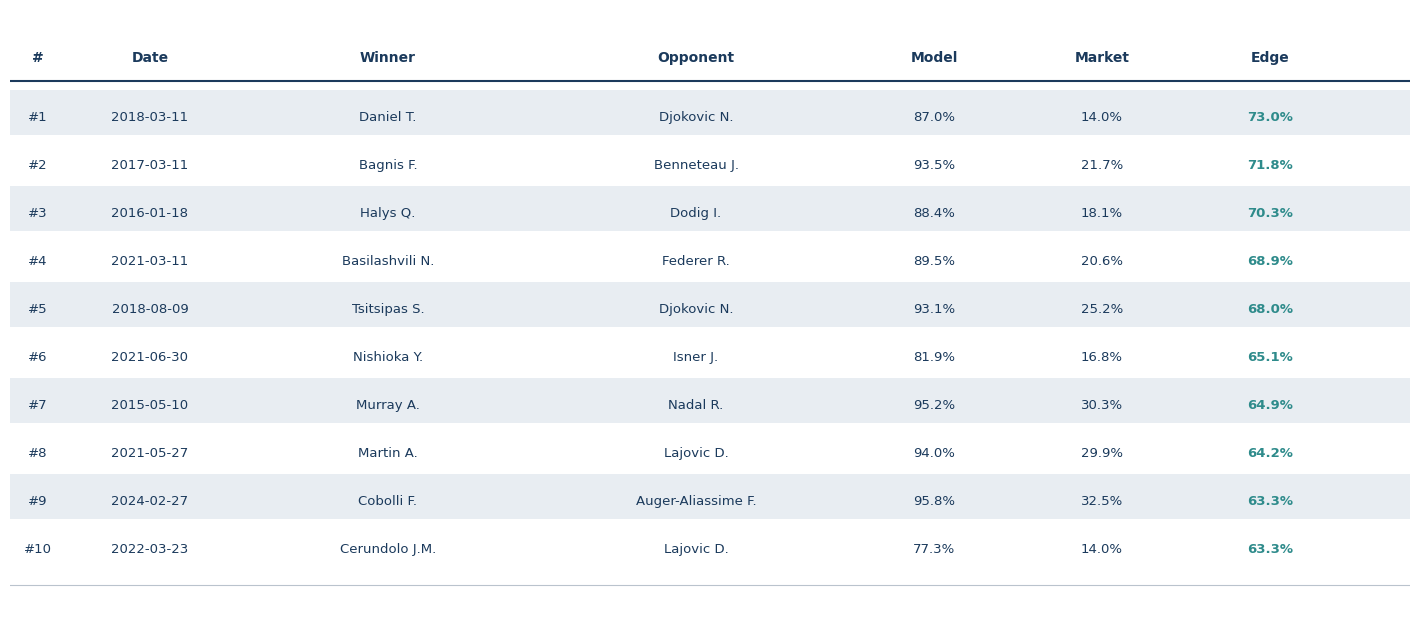

Saved to top10_value_bets.png


In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Prepare data
top_bets = merged[merged['y_true'] == 1].copy()
top_bets = top_bets.drop_duplicates(subset='match_id')
top_bets = top_bets.sort_values('edge', ascending=False).head(10)
top_bets['Date'] = pd.to_datetime(top_bets['Date']).dt.strftime('%Y-%m-%d')

# Theme colors matching your deck
DARK_NAVY = '#1B3A5C'
TEAL = '#2E8B8B'
LIGHT_BG = '#F0F4F8'
WHITE = '#FFFFFF'
LIGHT_GREY = '#E8EDF2'

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor(WHITE)
ax.set_facecolor(WHITE)
ax.axis('off')

# Column headers and data
columns = ['#', 'Date', 'Winner', 'Opponent', 'Model', 'Market', 'Edge']
col_widths = [0.04, 0.12, 0.22, 0.22, 0.12, 0.12, 0.12]
col_x = [sum(col_widths[:i]) + col_widths[i]/2 for i in range(len(col_widths))]

# Header row
header_y = 0.92
for i, (col, x) in enumerate(zip(columns, col_x)):
    ax.text(x, header_y, col,
            transform=ax.transAxes,
            ha='center', va='center',
            fontsize=10, fontweight='bold',
            color=DARK_NAVY,
            fontfamily='sans-serif')

# Header underline using plot instead of axhline
ax.plot([0, 1], [header_y - 0.04, header_y - 0.04],
        color=DARK_NAVY, linewidth=1.5,
        transform=ax.transAxes)

# Data rows
row_height = 0.08
for idx, (_, row) in enumerate(top_bets.iterrows()):
    y = header_y - 0.10 - idx * row_height
    
    # Alternating row background
    if idx % 2 == 0:
        rect = mpatches.FancyBboxPatch((0, y - 0.03), 1, row_height - 0.005,
                                        boxstyle="square,pad=0",
                                        facecolor=LIGHT_GREY, edgecolor='none',
                                        transform=ax.transAxes, zorder=0)
        ax.add_patch(rect)
    
    row_data = [
        f"#{idx+1}",
        row['Date'],
        row['player_name'],
        row['opponent_name'],
        f"{row['model_prob']:.1%}",
        f"{row['market_prob']:.1%}",
        f"{row['edge']:.1%}"
    ]
    
    for i, (val, x) in enumerate(zip(row_data, col_x)):
        # Edge column gets teal color
        color = TEAL if i == 6 else DARK_NAVY
        weight = 'bold' if i == 6 else 'normal'
        fontsize = 9.5
        
        ax.text(x, y, val,
                transform=ax.transAxes,
                ha='center', va='center',
                fontsize=fontsize,
                color=color,
                fontweight=weight,
                fontfamily='sans-serif')

# Bottom line
bottom_y = header_y - 0.10 - 10 * row_height + 0.02
ax.plot([0, 1], [bottom_y, bottom_y],
        color=DARK_NAVY, linewidth=0.8, alpha=0.3,
        transform=ax.transAxes)

plt.tight_layout(pad=0)
plt.savefig('top10_value_bets.png', dpi=200, bbox_inches='tight',
            facecolor=WHITE, edgecolor='none')
plt.show()
print("Saved to top10_value_bets.png")

## 6. Export Results for Visualizations

In [49]:
# Export unique matches for visualization scripts
comparison_unique = merged.drop_duplicates(subset='match_id', keep='first').copy()
comparison_unique.to_csv('../data/model_results/betting_comparison_unique.csv', index=False)

print(f"✓ Exported {len(comparison_unique):,} unique matches for visualizations")
print(f"✓ Saved to: ../data/model_results/betting_comparison_unique.csv")

✓ Exported 4,972 unique matches for visualizations
✓ Saved to: ../data/model_results/betting_comparison_unique.csv
